# A slicer for 3D printing: perimeters and infill

Before a print, a slicer reads the part, cuts it into layers, and turns every layer into the paths that the nozzle
follows. The example is a slicer for a chess rook: OpenCASCADE reads a STEP file and cuts the solid with a plane at each
layer's height. planex2d takes each section as a face and makes the toolpaths: five perimeters as offsets of the layer's
outline, and infill lines clipped to what is left inside, turned by 90° from layer to layer. Each toolpath, offset by
half the line width, is the bead of plastic the nozzle lays down. Lengths are in mm.

![A chess rook sliced into layers with perimeters and infill, built up layer by layer](../_static/gallery/slicer.gif){.result}

In [1]:
import math
import time
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML
import netgen.occ as occ
from ngsolve_webgpu.jupyter import Draw
import planex as px

## The part

The part is a chess rook, turned from a profile, with four slots in its crown, a bore from the top and a window
through its waist. It is written to a STEP file and read back from it, as a slicer would receive it.

In [2]:
profile = [(0, 0), (15, 0), (15, 3), (9, 8), (9, 28), (12, 31), (12, 40), (7, 40), (7, 25), (0, 25)]
side = px.QuickSketch(px.Plane(normal=(0, -1, 0), axis=(1, 0, 0))).Move(profile[0])
for p in profile[1:]:
    side.Line(p)
body = side.Close().Face().ToOCCFace().Revolve(occ.Axis((0, 0, 0), occ.Z), 360)
slot = occ.Box(occ.Pnt(-2.5, -20, 35), occ.Pnt(2.5, 20, 41))
window = occ.Cylinder(occ.Pnt(-20, 0, 18), occ.X, 2.5, 40)
rook = body - slot - slot.Rotate(occ.Axis((0, 0, 0), occ.Z), 90) - window
rook.WriteStep("rook.step")
part = occ.OCCGeometry("rook.step").shape
print("volume", round(part.mass, 3), "mm³,", len(part.faces), "faces")
Draw(part, euler_angles=[-64.62, 0.29, 72.18])

volume 11471.181 mm³, 25 faces


The part as the slicer read it: [rook.step](rook.step)

## A layer

Cutting the part with a plane at the layer's mid-height gives the section's faces, and projected onto the xy plane,
they are planex2d faces. Where the plane cuts the cone at the rook's foot, OpenCASCADE returns each circle as two half
circles, and planex2d reads them as one exact circle edge. **Check:** the layer's area is the section's area as
OpenCASCADE measures it.

In [3]:
def section(z):
    plane = px.QuickSketch(px.XY.Offset(z)).RectangleC(200, 200).Face().ToOCCFace()
    return part * plane


def layer(z):
    return px.Unify([px.Face(px.Project(f)) for f in section(z).faces])


for z in (1.0, 4.0, 18.0, 30.0, 37.0):
    print("z =", z, len(layer(z).faces), "pieces, planex2d", round(layer(z).mass, 6), "OCC",
          round(sum(f.mass for f in section(z).faces), 6))

z = 1.0 1 pieces, planex2d 706.858347 OCC 706.858347
z = 4.0 1 pieces, planex2d 598.284905 OCC 598.284905
z = 18.0 2 pieces, planex2d 165.640192 OCC 165.640192
z = 30.0 1 pieces, planex2d 226.194671 OCC 226.194671
z = 37.0 4 pieces, planex2d 197.162995 OCC 197.162995


## Toolpaths

A 0.25 nozzle lays lines `width` = 0.25 wide in layers `height` = 0.2 high. The rules:

- the k-th perimeter runs along the outline of the layer shrunk by (k + 1/2) line widths, which is the layer minus a
  band around its outline, the outline's offset;
- the infill fills the layer shrunk by the five perimeters with parallel lines spaced for 20 %, five line widths apart,
  found by intersecting each line with the outline and keeping the pieces inside;
- the bottom three layers are filled solid.

Every toolpath offset by half a line is its bead, and a compound keeps the beads as they are, overlapping where the
nozzle passes twice.

In [4]:
width = 0.25
height = 0.2


def outlines(shape):
    return [w for f in shape.faces for w in (f.outer, *f.inner)]


def shrunk(shape, d):
    return shape - px.Unify([w.Offset(d) for w in outlines(shape)])


def infill(region, angle, gap):
    if region.mass < 1e-9:
        return []
    (x0, y0), (x1, y1) = region.bounding_box
    cx, cy = (x0 + x1) / 2, (y0 + y1) / 2
    reach = math.hypot(x1 - x0, y1 - y0) / 2 + 1
    ux, uy = math.cos(math.radians(angle)), math.sin(math.radians(angle))
    lines = []
    for n in range(-int(reach / gap), int(reach / gap) + 1):
        x, y = cx - uy * n * gap, cy + ux * n * gap
        a, b = (x - reach * ux, y - reach * uy), (x + reach * ux, y + reach * uy)
        hits = sorted({round((v.h - a[0]) * ux + (v.v - a[1]) * uy, 9)
                       for f in region.faces for v in f.Intersections(px.Line(a, b))})
        for s0, s1 in zip(hits, hits[1:]):
            mid = (a[0] + (s0 + s1) / 2 * ux, a[1] + (s0 + s1) / 2 * uy)
            if any(f.Contains(mid) for f in region.faces):
                lines.append(px.Line((a[0] + s0 * ux, a[1] + s0 * uy), (a[0] + s1 * ux, a[1] + s1 * uy)))
    return lines


def toolpaths(n):
    z = (n + 0.5) * height
    region = layer(z)
    walls = [w for k in range(5) for w in outlines(shrunk(region, (k + 0.5) * width))]
    lines = infill(shrunk(region, 5 * width), 45 + 90 * n, width if n < 3 else 5 * width)
    return {"z": z, "area": region.mass, "perimeters": walls, "infill": lines}


def beads(paths):
    return {kind: px.Compound([w.Offset(width / 2) for w in paths[kind]]) for kind in ("perimeters", "infill")}

The beads of three layers: in the foot, through the window and in the crown, the perimeters red and the infill
yellow.

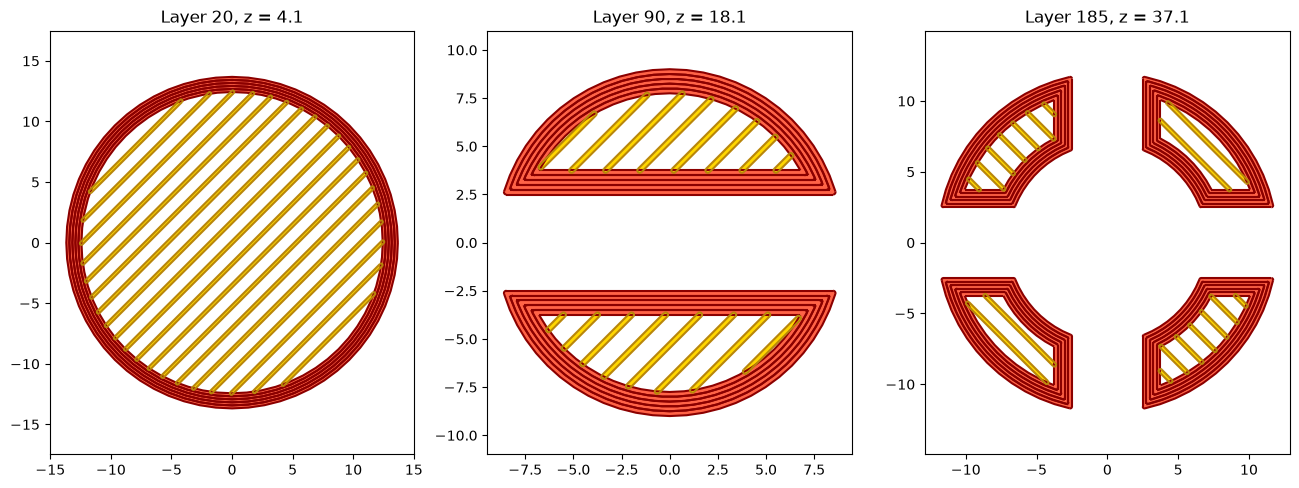

In [5]:
colors = {"perimeters": ("tomato", "darkred"), "infill": ("gold", "darkgoldenrod")}


def draw(ax, paths):
    for kind, compound in beads(paths).items():
        fill, edge = colors[kind]
        compound.Plot(ax=ax, face_col=fill, line_col=edge, arc_col=edge, spline_col=edge, legend=False)


fig, axes = plt.subplots(1, 3, figsize=(16, 5.5))
for ax, n in zip(axes, (20, 90, 185)):
    draw(ax, toolpaths(n))
    ax.set_title(f"Layer {n}, z = {(n + 0.5) * height:.1f}")
    ax.set_aspect("equal")
plt.show()

## All layers

The part's height is divided into layers of 0.2. **Check:** the layers' areas times the layer height add up to the
part's volume, up to the slicing error at the slopes. The length of the toolpaths gives the print time and the
filament.

In [6]:
start = time.perf_counter()
layers = [toolpaths(n) for n in range(round(40 / height))]
length = sum(w.mass for paths in layers for w in paths["perimeters"] + paths["infill"])
print(len(layers), "layers in", round(time.perf_counter() - start, 1), "s")
print("layers' volume", round(sum(p["area"] for p in layers) * height, 1), "mm³, part", round(part.mass, 1), "mm³")
print(round(length / 1000, 1), "m of toolpath,", round(length / 40 / 60), "min at 40 mm/s")
print(round(length * width * height / (math.pi * 1.75**2 / 4) / 1000, 2), "m of 1.75 mm filament")

200 layers in 1.6 s
layers' volume 11474.1 mm³, part 11471.2 mm³
115.1 m of toolpath, 48 min at 40 mm/s
2.39 m of 1.75 mm filament


## Layer by layer

The figure shows every third layer, with the perimeters' beads stacking up on the left, the layer's beads on the
right, and the infill turning from one layer to the next.

In [7]:
def edges_of(compound):
    shape = compound.ToShapely(0.02)
    polygons = getattr(shape, "geoms", [shape])
    return [list(ring.coords) for p in polygons for ring in (p.exterior, *p.interiors)]


plt.rcParams["animation.frame_format"] = "jpeg"
fig = plt.figure(figsize=(14, 6.5))
build = fig.add_subplot(1, 2, 1, projection="3d")
current = fig.add_subplot(1, 2, 2)
build.set_xlim(-16, 16)
build.set_ylim(-16, 16)
build.set_zlim(0, 40)
build.set_box_aspect((1, 1, 1.25))
shades = plt.cm.inferno


def frame(k):
    paths = layers[3 * k]
    for ring in edges_of(beads(paths)["perimeters"]):
        build.plot([x for x, y in ring], [y for x, y in ring], paths["z"], color=shades(0.2 + 0.7 * paths["z"] / 40),
                   lw=0.4)
    current.clear()
    draw(current, paths)
    current.set_xlim(-16, 16)
    current.set_ylim(-16, 16)
    current.set_aspect("equal", adjustable="box")
    current.set_title(f"Layer {3 * k}, z = {paths['z']:.1f}")


animation = FuncAnimation(fig, frame, frames=len(layers) // 3, interval=80)
plt.close(fig)
HTML(animation.to_jshtml())

## G-code

The output is the simplest G-code that a printer runs, with millimeters, absolute positions, relative extrusion, one
feed rate and no retraction. Each toolpath becomes a travel move to its start and extruding moves along its points, with
arcs as short chords. The filament for a move is its length times the line's width and height, divided by the filament's
cross-section. The comments are the ones PrusaSlicer writes, so its G-code viewer shows the layers and which lines are
perimeters and which infill. The part sits at the bed's center. The filament in the file must be what the toolpaths'
length gave above.

In [8]:
bed = (125.0, 105.0)
feed = 40 * 60
filament = math.pi * 1.75**2 / 4


def chords(w):
    shape = w.ToShapely(0.01)
    return [list(part.coords) for part in getattr(shape, "geoms", [shape])]


gcode = ["; a chess rook, sliced with planex2d", "G21", "G90", "M83", "M104 S210", "M140 S60", "M190 S60", "M109 S210",
         "G28", f"G1 F{feed}"]
extruded = 0.0
for n, paths in enumerate(layers):
    top = paths["z"] + height / 2
    gcode += [";LAYER_CHANGE", f";Z:{top:.2f}", f";HEIGHT:{height}", f"G1 Z{top:.3f} F{feed}"]
    for kind, label in (("perimeters", "Perimeter"), ("infill", "Solid infill" if n < 3 else "Internal infill")):
        gcode += [f";TYPE:{label}", f";WIDTH:{width}"]
        for w in paths[kind]:
            for points in chords(w):
                gcode.append(f"G0 X{points[0][0] + bed[0]:.3f} Y{points[0][1] + bed[1]:.3f}")
                for p, q in zip(points, points[1:]):
                    e = math.dist(p, q) * width * height / filament
                    extruded += e
                    gcode.append(f"G1 X{q[0] + bed[0]:.3f} Y{q[1] + bed[1]:.3f} E{e:.5f}")
gcode += ["M104 S0", "M140 S0", "M84"]
with open("rook.gcode", "w") as file:
    file.write("\n".join(gcode) + "\n")
print("rook.gcode:", len(gcode), "lines,", round(extruded / 1000, 3), "m of filament")
print("from the toolpaths' length", round(length * width * height / filament / 1000, 3), "m")

rook.gcode: 95342 lines, 2.391 m of filament
from the toolpaths' length 2.392 m


The G-code: [rook.gcode](rook.gcode)

## In PrusaSlicer

The file is valid G-code. Opened in PrusaSlicer's G-code viewer, it shows all 200 layers with the crown's slots, the
bore and the window, and the viewer counts the same 2.39 m (7.16 g) of filament. It can be printed as it is on a printer
with a 0.25 mm nozzle and a 250 × 210 bed, whose middle is (125, 105).

![The rook's G-code in PrusaSlicer's G-code viewer](../_static/gallery/slicer-prusaslicer.jpg){.result}

In [9]:
import sys
sys.path.insert(0, "..")
from gallery import save_scene, save_figure, save_animation, HIDDEN
save_animation(animation, "slicer", dpi=60, bare=True)

'/workspace/planex/documentation/docs/_static/gallery/slicer.gif'